In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [2]:
df = pd.read_csv("covid_data.csv")
df.head()

,country,date,total_cases,new_cases,new_cases_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,total_deaths,new_deaths,...,population,population_density,median_age,life_expectancy,gdp_per_capita,extreme_poverty,diabetes_prevalence,handwashing_facilities,hospital_beds_per_thousand,human_development_index
0,Afghanistan,2020-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
1,Afghanistan,2020-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
2,Afghanistan,2020-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
3,Afghanistan,2020-01-04,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN
4,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,...,40578847.0,62.215549,16.752001,65.616997,1964.452271,NaN,11.7,51.938343,0.35,NaN


In [3]:
df.shape

(629868, 61)

In [4]:
df.columns

Index(['country', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed',
       'total_cases_per_million', 'new_cases_per_million',
       'new_cases_smoothed_per_million', 'total_deaths', 'new_deaths',
       'new_deaths_smoothed', 'total_deaths_per_million',
       'new_deaths_per_million', 'new_deaths_smoothed_per_million',
       'excess_mortality', 'excess_mortality_cumulative',
       'excess_mortality_cumulative_absolute',
       'excess_mortality_cumulative_per_million', 'hosp_patients',
       'hosp_patients_per_million', 'weekly_hosp_admissions',
       'weekly_hosp_admissions_per_million', 'icu_patients',
       'icu_patients_per_million', 'weekly_icu_admissions',
       'weekly_icu_admissions_per_million', 'stringency_index',
       'reproduction_rate', 'total_tests', 'new_tests',
       'total_tests_per_thousand', 'new_tests_per_thousand',
       'new_tests_smoothed', 'new_tests_smoothed_per_thousand',
       'positive_rate', 'tests_per_case', 'total_vaccinations',
    

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 629868 entries, 0 to 629867
Data columns (total 61 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   country                                     629868 non-null  str    
 1   date                                        629868 non-null  str    
 2   total_cases                                 617520 non-null  float64
 3   new_cases                                   612628 non-null  float64
 4   new_cases_smoothed                          611419 non-null  float64
 5   total_cases_per_million                     617520 non-null  float64
 6   new_cases_per_million                       612628 non-null  float64
 7   new_cases_smoothed_per_million              611419 non-null  float64
 8   total_deaths                                617520 non-null  float64
 9   new_deaths                                  613891 non-null  float64
 10  new_dea

In [6]:
df.isnull().sum()

country                            0
date                               0
total_cases                    12348
new_cases                      17240
new_cases_smoothed             18449
                               ...  
extreme_poverty               225135
diabetes_prevalence            99539
handwashing_facilities        323367
hospital_beds_per_thousand    200357
human_development_index       629868
Length: 61, dtype: int64

In [7]:
df.isnull().sum().sum()

np.int64(21134161)

In [8]:
(df.isnull().sum()/len(df))*100

country                         0.000000
date                            0.000000
total_cases                     1.960411
new_cases                       2.737081
new_cases_smoothed              2.929026
                                 ...    
extreme_poverty                35.743203
diabetes_prevalence            15.803152
handwashing_facilities         51.338852
hospital_beds_per_thousand     31.809363
human_development_index       100.000000
Length: 61, dtype: float64

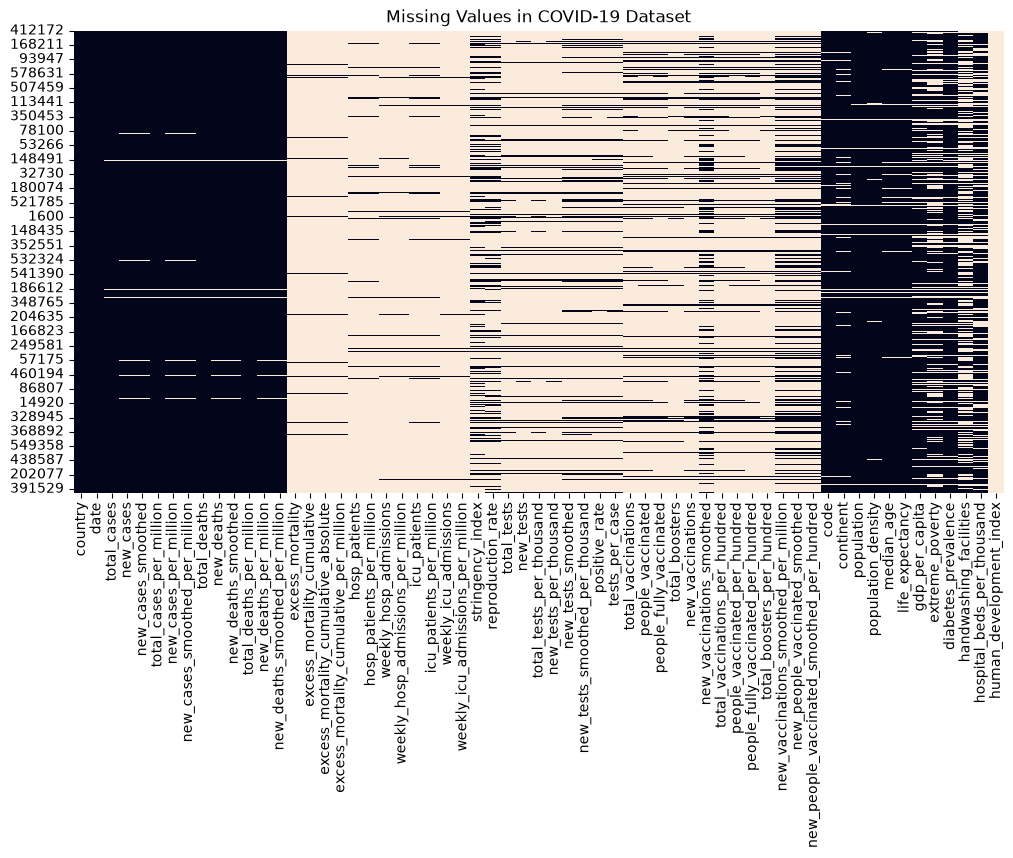

In [9]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull().sample(1000),cbar=False)
plt.title("Missing Values in COVID-19 Dataset")
plt.show()

In [10]:
df.isnull().sum().sort_values(ascending=False).head(15)

human_development_index                    629868
weekly_icu_admissions                      618875
weekly_icu_admissions_per_million          618875
excess_mortality_cumulative_per_million    615976
excess_mortality                           615942
excess_mortality_cumulative                615942
excess_mortality_cumulative_absolute       615942
weekly_hosp_admissions_per_million         605371
weekly_hosp_admissions                     605371
icu_patients                               590752
icu_patients_per_million                   590752
hosp_patients_per_million                  589212
hosp_patients                              589212
total_boosters                             571084
total_boosters_per_hundred                 571084
dtype: int64

In [11]:
df.drop(columns=['human_development_index'],inplace=True)

In [12]:
df.shape

(629868, 60)

In [13]:
missing_values=df.isnull().sum()
missing_values=missing_values[missing_values>0]
missing_values.sort_values(ascending=False).head(15)

weekly_icu_admissions_per_million          618875
weekly_icu_admissions                      618875
excess_mortality_cumulative_per_million    615976
excess_mortality_cumulative                615942
excess_mortality                           615942
excess_mortality_cumulative_absolute       615942
weekly_hosp_admissions                     605371
weekly_hosp_admissions_per_million         605371
icu_patients                               590752
icu_patients_per_million                   590752
hosp_patients_per_million                  589212
hosp_patients                              589212
total_boosters_per_hundred                 571084
total_boosters                             571084
new_vaccinations                           560992
dtype: int64

In [14]:
missing_percent=(df.isnull().sum()/len(df))*100
missing_percet=missing_percent.sort_values(ascending=False)
missing_percent.head(15)

country                             0.000000
date                                0.000000
total_cases                         1.960411
new_cases                           2.737081
new_cases_smoothed                  2.929026
total_cases_per_million             1.960411
new_cases_per_million               2.737081
new_cases_smoothed_per_million      2.929026
total_deaths                        1.960411
new_deaths                          2.536563
new_deaths_smoothed                 2.728984
total_deaths_per_million            1.960411
new_deaths_per_million              2.536563
new_deaths_smoothed_per_million     2.728984
excess_mortality                   97.789061
dtype: float64

In [15]:
high_missing=missing_percent[missing_percent>90]
high_missing

excess_mortality                           97.789061
excess_mortality_cumulative                97.789061
excess_mortality_cumulative_absolute       97.789061
excess_mortality_cumulative_per_million    97.794459
hosp_patients                              93.545314
hosp_patients_per_million                  93.545314
weekly_hosp_admissions                     96.110772
weekly_hosp_admissions_per_million         96.110772
icu_patients                               93.789810
icu_patients_per_million                   93.789810
weekly_icu_admissions                      98.254714
weekly_icu_admissions_per_million          98.254714
total_boosters                             90.667251
total_boosters_per_hundred                 90.667251
dtype: float64

In [16]:
df.drop(columns=high_missing.index,inplace=True)

In [17]:
df.shape

(629868, 46)

In [18]:
df.isnull().sum().sort_values(ascending=False).head(15)

new_vaccinations                       560992
new_tests                              554465
new_tests_per_thousand                 554465
people_fully_vaccinated                552857
people_fully_vaccinated_per_hundred    552857
people_vaccinated                      550857
people_vaccinated_per_hundred          550857
total_tests_per_thousand               550481
total_tests                            550481
total_vaccinations                     546646
total_vaccinations_per_hundred         546646
tests_per_case                         529218
positive_rate                          528308
new_tests_smoothed                     525903
new_tests_smoothed_per_thousand        525903
dtype: int64

In [19]:
df.dtypes.value_counts()

float64    42
str         4
Name: count, dtype: int64

In [20]:
numeric_columns = df.select_dtypes(include='number').columns

df[numeric_columns] = df[numeric_columns].fillna(
    df[numeric_columns].median()
)

In [21]:
df.isnull().sum().sum()

np.int64(72208)

In [22]:
df.isnull().sum()[df.isnull().sum()>0]

code         26184
continent    46024
dtype: int64

In [23]:
df['code']=df['code'].fillna('unknown')
df['continent']=df['continent'].fillna('unknown')

In [24]:
df.isnull().sum().sum()

np.int64(0)

In [25]:
top_countries = (
    df.groupby('country')['total_cases']
    .max()
    .sort_values(ascending=False)
    .head(10)
)

top_countries

country
World                                                  779452126.0
World excl. China                                      680070365.0
World excl. China and South Korea                      645498492.0
World excl. China, South Korea, Japan and Singapore    608688765.0
High-income countries                                  458126754.0
Asia                                                   302378747.0
Upper-middle-income countries                          257734184.0
Europe                                                 255035575.0
Asia excl. China                                       202996986.0
European Union (27)                                    187032399.0
Name: total_cases, dtype: float64

In [26]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [27]:
import plotly.express as px

latest_data = df.sort_values('date').groupby('country').tail(1)

fig = px.choropleth(
    latest_data,
    locations='code',
    color='total_cases',
    hover_name='country',
    color_continuous_scale='Reds',
    title='COVID-19 Total Cases Around the World',
    projection='natural earth'
)

fig.show()

In [28]:
top_deaths = (
    df.groupby('country')['total_deaths']
    .max()
    .sort_values(ascending=False)
    .head(10)
)

top_deaths

country
World                                                  7117473.0
World excl. China                                      6995075.0
World excl. China and South Korea                      6959141.0
World excl. China, South Korea, Japan and Singapore    6882423.0
High-income countries                                  3506336.0
Upper-middle-income countries                          2768510.0
Europe                                                 2112331.0
North America                                          1718967.0
Asia                                                   1637931.0
Asia excl. China                                       1515533.0
Name: total_deaths, dtype: float64

In [29]:
import plotly.graph_objects as go

# Select actual countries only
country_data = df[df['continent'] != 'Unknown'].copy()

# Find top 10 countries by total deaths
top_deaths = (
    country_data.groupby('country')['total_deaths']
    .max()
    .nlargest(10)
    .reset_index()
    .sort_values('total_deaths', ascending=False)
)

# Create lollipop lines
x_stems = []
y_stems = []

for row in top_deaths.itertuples():
    x_stems.extend([0, row.total_deaths, None])
    y_stems.extend([row.country, row.country, None])

# Create beautiful figure
fig = go.Figure()

# Add connecting lines
fig.add_trace(go.Scatter(
    x=x_stems,
    y=y_stems,
    mode='lines',
    line=dict(color='#64748B', width=3),
    hoverinfo='skip',
    showlegend=False
))

# Add glowing-style dots
fig.add_trace(go.Scatter(
    x=top_deaths['total_deaths'],
    y=top_deaths['country'],
    mode='markers+text',
    marker=dict(
        size=19,
        color=top_deaths['total_deaths'],
        colorscale='Plasma',
        showscale=True,
        colorbar=dict(title='Total Deaths'),
        line=dict(color='white', width=1.5)
    ),
    text=[
        f'{value / 1_000_000:.2f}M'
        for value in top_deaths['total_deaths']
    ],
    textposition='middle right',
    textfont=dict(color='white', size=12),
    hovertemplate='<b>%{y}</b><br>Total Deaths: %{x:,.0f}<extra></extra>',
    showlegend=False
))

# Customize the design
fig.update_layout(
    title=dict(
        text='🌍 COVID-19 | Top 10 Countries by Total Deaths',
        x=0.5,
        font=dict(size=23, color='#FFFFFF')
    ),
    template='plotly_dark',
    paper_bgcolor='#0B1020',
    plot_bgcolor='#111827',
    height=650,
    width=1100,
    xaxis_title='Total Reported Deaths',
    yaxis_title='',
    yaxis=dict(autorange='reversed'),
    font=dict(family='Arial', color='white', size=13),
    margin=dict(l=120, r=100, t=100, b=70),
    showlegend=False
)

fig.show()

In [30]:
daily_cases = df[df['country'] == 'World'].copy()

daily_cases['date'] = pd.to_datetime(daily_cases['date'])

daily_cases = daily_cases.sort_values('date')

fig = px.area(
    daily_cases,
    x='date',
    y='new_cases',
    title='🌍 Global COVID-19 Daily New Cases',
    color_discrete_sequence=['#FF4B8B']
)

fig.update_layout(
    template='plotly_dark',
    paper_bgcolor='#0B1020',
    plot_bgcolor='#111827',
    title_x=0.5,
    height=600,
    xaxis_title='Date',
    yaxis_title='Daily New Cases'
)

fig.show()

In [31]:
vaccination = df[df['country'] == 'World'].copy()

vaccination['date'] = pd.to_datetime(vaccination['date'])

vaccination = vaccination.sort_values('date')

fig = px.area(
    vaccination,
    x='date',
    y='people_fully_vaccinated',
    title='💉 Global COVID-19 Fully Vaccinated People',
    color_discrete_sequence=['#00E5A8']
)

fig.update_layout(
    template='plotly_dark',
    paper_bgcolor='#0B1020',
    plot_bgcolor='#111827',
    title_x=0.5,
    height=600,
    xaxis_title='Date',
    yaxis_title='Fully Vaccinated People'
)

fig.show()

In [32]:
country_data = df[
    (df['continent'] != 'Unknown') &
    (df['code'].str.len() == 3)
].copy()

country_latest = (
    country_data.sort_values('date')
    .groupby('country')
    .tail(1)
)

country_latest.shape

(237, 46)

In [33]:
features = [
    'population_density',
    'median_age',
    'life_expectancy',
    'gdp_per_capita',
    'diabetes_prevalence',
    'hospital_beds_per_thousand'
]

target = 'total_cases_per_million'

X = country_latest[features]
y = country_latest[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Missing values:", X.isnull().sum().sum() + y.isnull().sum())

Features shape: (237, 6)
Target shape: (237,)
Missing values: 0


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (189, 6)
Testing data: (48, 6)


In [35]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [36]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Cases': y_test.values,
    'Predicted Cases': y_pred
})

results.head(10)

,Actual Cases,Predicted Cases
0,964.7438,14353.803343
1,5013.2583,86441.942015
2,17132.8540,32097.410247
3,4096.4330,8923.043686
4,119264.5100,273502.636500
5,421673.2800,503966.360000
6,456183.3800,115788.680107
7,641351.6000,358220.534000
8,293443.2200,330549.525600
9,547083.9400,349710.083600


In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 99478.39249727501
RMSE: 136085.82579011307
R2 Score: 0.5577172430246768


In [38]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=y_test,
    y=y_pred,
    mode='markers',
    marker=dict(
        size=12,
        color=y_test,
        colorscale='Plasma',
        showscale=True
    ),
    name='Predictions'
))

fig.update_layout(
    title='🌍 Actual vs Predicted COVID-19 Cases',
    template='plotly_dark',
    paper_bgcolor='#0B1020',
    plot_bgcolor='#111827',
    title_x=0.5,
    xaxis_title='Actual Cases per Million',
    yaxis_title='Predicted Cases per Million',
    height=650
)

fig.show()

In [39]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=True
)

fig = px.bar(
    importance,
    x='Importance',
    y='Feature',
    orientation='h',
    color='Importance',
    color_continuous_scale='Plasma',
    title='🌟 Random Forest - Feature Importance'
)

fig.update_layout(
    template='plotly_dark',
    paper_bgcolor='#0B1020',
    plot_bgcolor='#111827',
    title_x=0.5,
    height=550,
    xaxis_title='Importance Score',
    yaxis_title='Features'
)

fig.show()

# COVID-19 Data Science Project

## Project Overview
This project analyzes global COVID-19 data using Python, Pandas, NumPy, Seaborn and Plotly.

## Data Cleaning
- Checked dataset shape and information.
- Identified missing values.
- Analyzed missing-value percentages.
- Removed columns with very high missing values.
- Filled numerical missing values using median.
- Filled categorical missing values using "Unknown".

## Exploratory Data Analysis (EDA)
- Analyzed COVID-19 cases worldwide.
- Explored total deaths by country.
- Studied global daily new cases.
- Analyzed global vaccination trends.

## Data Visualization
Created interactive visualizations:
- Global COVID-19 World Map.
- Top 10 Countries by Total Deaths.
- Global Daily New Cases.
- Global Fully Vaccinated People.
- Actual vs Predicted COVID-19 Cases.
- Feature Importance.

## Machine Learning
- Algorithm: Random Forest Regressor
- Training Data: 189 countries
- Testing Data: 48 countries
- Features: 6
- Target: Total COVID-19 Cases per Million

## Model Evaluation
- MAE: 99,478.39
- RMSE: 136,085.83
- R² Score: 0.558

## Conclusion
This project helped explore global COVID-19 trends, understand data cleaning, create interactive visualizations and build a machine learning regression model.

The model explains approximately 55.8% of the variation in the test data. Its predictions have limitations and should not be considered reliable forecasts.

## Limitations
- Some columns contained a large number of missing values.
- Median imputation may affect the original data distribution.
- The model uses only 237 country-level records.
- The results show associations, not causal relationships.